# Build EMOPAIR Dataset

Using the results from `validate_LLMs.ipynb`, we can now build the EMOPAIR dataset.

Based on the Alt-Test results, we will use the following LLMs as annotators:
- Valence: No LLMs passed the Alt-Test for valence, so we will not use any LLMs as annotators for this dimension.
- Arousal: GPT-5.1
- Dominance: claude-sonnet-4-5

For Valence, we will use the prior EMOBANK data. 

In [1]:
import os
import pandas as pd 
import pairadigm as pdm
import random 

import dotenv

dotenv.load_dotenv(dotenv_path='/fs/clip-projects/clip-k12/mlchrzan/.env')

/fs/clip-projects/clip-airreading/mlchrzan/miniconda/envs/emopair/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


True

## Prep

In [2]:
# Load EMOBANK data to get the original text data
emobank = pd.read_csv('Data/emobank.csv')
emobank

,id,split,V,A,D,text
0,110CYL068_1036_1079,train,3.00,3.00,3.20,"Remember what she said in my last letter? """
1,110CYL068_1079_1110,test,2.80,3.10,2.80,If I wasn't working here.
2,110CYL068_1127_1130,train,3.00,3.00,3.00,".."""
3,110CYL068_1137_1188,train,3.44,3.00,3.22,Goodwill helps people get off of public assist...
4,110CYL068_1189_1328,train,3.55,3.27,3.46,Sherry learned through our Future Works class ...
...,...,...,...,...,...,...
10057,wwf12_4531_4624,train,3.00,3.50,3.00,Please let it be a constant reminder of all yo...
10058,wwf12_501_591,train,3.80,3.40,3.60,That’s why I want to extend my appreciation fo...
10059,wwf12_592_691,train,3.00,3.00,3.10,And why I’m writing you today to ask you to re...
10060,wwf12_702_921,train,3.33,3.44,3.44,"In fact, I want to urge you to strengthen your..."


In [15]:
# Load CGCOT Prompts
with open('Data/cgcot_prompts/valence.txt', 'r') as file:
    val_prompts = file.read().splitlines()

with open('Data/cgcot_prompts/arousal.txt', 'r') as file:
    aro_prompts = file.read().splitlines()

with open('Data/cgcot_prompts/dominance.txt', 'r') as file:
    dom_prompts = file.read().splitlines()

## Build Pairs for pairadigms

In [3]:
# NOTE: There are issues with the seeds where this does not guarantee the same pairs across runs. So here we will just load the pairs from a csv file that was generated with a fixed seed.
all_pairs = pd.read_csv('emopair_pairs.csv')

### Within split pairs

In [9]:
train_pairs = pdm.pair_items(emobank.loc[emobank['split'] == 'train', 'id'].reset_index(drop=True), num_pairs_per_item=10)
dev_pairs = pdm.pair_items(emobank.loc[emobank['split'] == 'dev', 'id'].reset_index(drop=True), num_pairs_per_item=15)
test_pairs = pdm.pair_items(emobank.loc[emobank['split'] == 'test', 'id'].reset_index(drop=True), num_pairs_per_item=15)
print(f"Number of training pairs: {len(train_pairs)}")
print(f"Number of validation pairs: {len(dev_pairs)}")
print(f"Number of test pairs: {len(test_pairs)}")

Number of training pairs: 46643
Number of validation pairs: 8482
Number of test pairs: 8507


### Between split pairs

In [10]:
train_items = train_pairs['item1'].unique()
dev_items = dev_pairs['item1'].unique()
test_items = test_pairs['item1'].unique()

# Generate mixed pairs where item1 and item2 come from different splits
mixed_pairs = pd.DataFrame(columns=['item1', 'item2', 'item1_split', 'item2_split'])

# For reproducibility
random.seed(42)

# Helper to pair each item with n items from a specific split
def add_unique_mixed_pairs_per_split(item1_list, item1_split, target_items, target_split, n_pairs, mixed_pairs):
    """
    Pair each item in item1_list with n_pairs items from target_items (target_split).
    """
    for item1 in item1_list:
        count = 0
        attempts = 0
        
        while count < n_pairs and attempts < 100*n_pairs:
            item2 = random.choice(list(target_items))
            
            # Check for duplicates
            if mixed_pairs[(mixed_pairs['item1'] == item1) & (mixed_pairs['item2'] == item2)].empty:
                mixed_pairs = pd.concat([
                    mixed_pairs,
                    pd.DataFrame([{
                        'item1': item1,
                        'item2': item2,
                        'item1_split': item1_split,
                        'item2_split': target_split
                    }])
                ], ignore_index=True)
                count += 1
            attempts += 1
    
    return mixed_pairs

# Number of pairs per split
n_pairs_per_split = 2

# Train items: pair with dev and test
mixed_pairs = add_unique_mixed_pairs_per_split(train_items, 'train', dev_items, 'dev', n_pairs_per_split, mixed_pairs)
mixed_pairs = add_unique_mixed_pairs_per_split(train_items, 'train', test_items, 'test', n_pairs_per_split, mixed_pairs)

# Dev items: pair with train and test
mixed_pairs = add_unique_mixed_pairs_per_split(dev_items, 'dev', train_items, 'train', n_pairs_per_split, mixed_pairs)
mixed_pairs = add_unique_mixed_pairs_per_split(dev_items, 'dev', test_items, 'test', n_pairs_per_split, mixed_pairs)

# Test items: pair with train and dev
mixed_pairs = add_unique_mixed_pairs_per_split(test_items, 'test', train_items, 'train', n_pairs_per_split, mixed_pairs)
mixed_pairs = add_unique_mixed_pairs_per_split(test_items, 'test', dev_items, 'dev', n_pairs_per_split, mixed_pairs)

mixed_pairs

,item1,item2,item1_split,item2_split
0,SemEval_1183,captured_moments_23645_23749,train,dev
1,SemEval_1183,20020731-nyt_23147_23178,train,dev
2,Fermentation_HR5034_10829_11054,Black_and_white_17324_17418,train,dev
3,Fermentation_HR5034_10829_11054,lessig_blog-carbon_5701_5764,train,dev
4,NYTnewswire9_2888_3030,114CUL058_163_285,train,dev
...,...,...,...,...
40231,wsj_2465_3356_3593,easy_money_794_895,test,dev
40232,sucker_2227_2315,118CWL048_107_216,test,dev
40233,sucker_2227_2315,SemEval_536,test,dev
40234,wsj_0159_279_412,NYTnewswire1_3229_3348,test,dev


### Combine all pairs

In [11]:
train_pairs['item1_split'] = 'train'
dev_pairs['item1_split'] = 'dev'
test_pairs['item1_split'] = 'test'
train_pairs['item2_split'] = 'train'
dev_pairs['item2_split'] = 'dev'
test_pairs['item2_split'] = 'test'

all_pairs = pd.concat([train_pairs, dev_pairs, test_pairs, mixed_pairs], ignore_index=True)
all_pairs

,item1,item2,item1_split,item2_split
0,SemEval_1183,SemEval_708,train,train
1,Fermentation_HR5034_10829_11054,Nathans_Bylichka_18921_19023,train,train
2,NYTnewswire9_2888_3030,detroit_13679_13703,train,train
3,Black_and_white_11547_11636,captured_moments_1674_1777,train,train
4,cable_spool_fort_8754_8800,cable_spool_fort_8980_8989,train,train
...,...,...,...,...
103863,wsj_2465_3356_3593,easy_money_794_895,test,dev
103864,sucker_2227_2315,118CWL048_107_216,test,dev
103865,sucker_2227_2315,SemEval_536,test,dev
103866,wsj_0159_279_412,NYTnewswire1_3229_3348,test,dev


In [12]:
# Join the text data from emobank for item1 and item2
all_pairs = all_pairs.merge(emobank[['id', 'text']], left_on='item1', right_on='id', how='left').rename(columns={'text': 'item1_text'}).drop(columns=['id'])
all_pairs = all_pairs.merge(emobank[['id', 'text']], left_on='item2', right_on='id', how='left').rename(columns={'text': 'item2_text'}).drop(columns=['id'])
all_pairs

,item1,item2,item1_split,item2_split,item1_text,item2_text
0,SemEval_1183,SemEval_708,train,train,Texan allegedly joined Somalia rebel plot,Peretz orders IDF to respond with force to nor...
1,Fermentation_HR5034_10829_11054,Nathans_Bylichka_18921_19023,train,train,Judd Wallenbrock said... Tom -- thanks so much...,"Holding Dvorov’s directions, Nepthys took us a..."
2,NYTnewswire9_2888_3030,detroit_13679_13703,train,train,He earned a doctorate in history from Stanford...,You gotta be kidding me!
3,Black_and_white_11547_11636,captured_moments_1674_1777,train,train,Crisp whiteness on the other hand expresses a ...,"I took mine home, where they sat above my comp..."
4,cable_spool_fort_8754_8800,cable_spool_fort_8980_8989,train,train,"""Nah."" Chad said, ""We're gonna be in trouble.""",You suck.
...,...,...,...,...,...,...
103863,wsj_2465_3356_3593,easy_money_794_895,test,dev,"Robert Merkel, a former U.S. attorney handling...","His tan was obviously deep and old, but it loo..."
103864,sucker_2227_2315,118CWL048_107_216,test,dev,"But then I thought, surely after all the other...",We know that children do better when they have...
103865,sucker_2227_2315,SemEval_536,test,dev,"But then I thought, surely after all the other...",Bernhard set to leave Volkswagen
103866,wsj_0159_279_412,NYTnewswire1_3229_3348,test,dev,"1% of Dunkin' common shares, on a fully dilute...",Jose went into Wednesday's game hitting .304 a...


In [13]:
# Join the V, A, D ratings from emobank for item1 and item2
all_pairs = all_pairs.merge(emobank[['id', 'V']], left_on='item1', right_on='id', how='left').rename(columns={'V': 'item1_V'}).drop(columns=['id'])
all_pairs = all_pairs.merge(emobank[['id', 'A']], left_on='item1', right_on='id', how='left').rename(columns={'A': 'item1_A'}).drop(columns=['id'])
all_pairs = all_pairs.merge(emobank[['id', 'D']], left_on='item1', right_on='id', how='left').rename(columns={'D': 'item1_D'}).drop(columns=['id'])
all_pairs = all_pairs.merge(emobank[['id', 'V']], left_on='item2', right_on='id', how='left').rename(columns={'V': 'item2_V'}).drop(columns=['id'])
all_pairs = all_pairs.merge(emobank[['id', 'A']], left_on='item2', right_on='id', how='left').rename(columns={'A': 'item2_A'}).drop(columns=['id'])
all_pairs = all_pairs.merge(emobank[['id', 'D']], left_on='item2', right_on='id', how='left').rename(columns={'D': 'item2_D'}).drop(columns=['id'])

# Rearrange the columns to have pair_id, item1, item2, item1_split, item2_split, item1_text, item2_text, item1_V, item2_V, item1_A, item2_A, item1_D, item2_D

all_pairs = all_pairs[['item1', 'item2', 'item1_split', 'item2_split', 'item1_text', 'item2_text', 'item1_V', 'item2_V', 'item1_A', 'item2_A', 'item1_D', 'item2_D']]

all_pairs   

,item1,item2,item1_split,item2_split,item1_text,item2_text,item1_V,item2_V,item1_A,item2_A,item1_D,item2_D
0,SemEval_1183,SemEval_708,train,train,Texan allegedly joined Somalia rebel plot,Peretz orders IDF to respond with force to nor...,2.80,2.78,2.80,3.11,2.90,3.11
1,Fermentation_HR5034_10829_11054,Nathans_Bylichka_18921_19023,train,train,Judd Wallenbrock said... Tom -- thanks so much...,"Holding Dvorov’s directions, Nepthys took us a...",3.20,3.00,3.10,2.90,3.40,2.90
2,NYTnewswire9_2888_3030,detroit_13679_13703,train,train,He earned a doctorate in history from Stanford...,You gotta be kidding me!,3.00,2.70,3.14,3.90,3.14,3.00
3,Black_and_white_11547_11636,captured_moments_1674_1777,train,train,Crisp whiteness on the other hand expresses a ...,"I took mine home, where they sat above my comp...",3.40,3.22,3.10,2.78,3.10,3.33
4,cable_spool_fort_8754_8800,cable_spool_fort_8980_8989,train,train,"""Nah."" Chad said, ""We're gonna be in trouble.""",You suck.,2.62,2.00,3.12,3.57,2.87,3.86
...,...,...,...,...,...,...,...,...,...,...,...,...
103863,wsj_2465_3356_3593,easy_money_794_895,test,dev,"Robert Merkel, a former U.S. attorney handling...","His tan was obviously deep and old, but it loo...",2.67,3.00,3.11,2.80,3.11,3.00
103864,sucker_2227_2315,118CWL048_107_216,test,dev,"But then I thought, surely after all the other...",We know that children do better when they have...,2.90,3.22,2.60,3.00,2.90,2.89
103865,sucker_2227_2315,SemEval_536,test,dev,"But then I thought, surely after all the other...",Bernhard set to leave Volkswagen,2.90,2.70,2.60,2.60,2.90,3.10
103866,wsj_0159_279_412,NYTnewswire1_3229_3348,test,dev,"1% of Dunkin' common shares, on a fully dilute...",Jose went into Wednesday's game hitting .304 a...,2.90,3.12,3.00,3.12,2.60,3.12


In [14]:
# Check that no item has 3 underscores in its id
assert not all_pairs['item1'].astype(str).str.contains('___').any(), "item1 contains an id with 3 underscores"
assert not all_pairs['item2'].astype(str).str.contains('___').any(), "item2 contains an id with 3 underscores"

In [15]:
# Create a "pair_id" column that uniquely identifies each pair by concatenating item1 and item2 IDs with 3 underscores as a separator
all_pairs['pair_id'] = all_pairs['item1'].astype(str) + '___' + all_pairs['item2'].astype(str)

# Put pair_id as the first column
cols = ['pair_id'] + [col for col in all_pairs.columns if col != 'pair_id']
all_pairs = all_pairs[cols]

all_pairs

,pair_id,item1,item2,item1_split,item2_split,item1_text,item2_text,item1_V,item2_V,item1_A,item2_A,item1_D,item2_D
0,SemEval_1183___SemEval_708,SemEval_1183,SemEval_708,train,train,Texan allegedly joined Somalia rebel plot,Peretz orders IDF to respond with force to nor...,2.80,2.78,2.80,3.11,2.90,3.11
1,Fermentation_HR5034_10829_11054___Nathans_Byli...,Fermentation_HR5034_10829_11054,Nathans_Bylichka_18921_19023,train,train,Judd Wallenbrock said... Tom -- thanks so much...,"Holding Dvorov’s directions, Nepthys took us a...",3.20,3.00,3.10,2.90,3.40,2.90
2,NYTnewswire9_2888_3030___detroit_13679_13703,NYTnewswire9_2888_3030,detroit_13679_13703,train,train,He earned a doctorate in history from Stanford...,You gotta be kidding me!,3.00,2.70,3.14,3.90,3.14,3.00
3,Black_and_white_11547_11636___captured_moments...,Black_and_white_11547_11636,captured_moments_1674_1777,train,train,Crisp whiteness on the other hand expresses a ...,"I took mine home, where they sat above my comp...",3.40,3.22,3.10,2.78,3.10,3.33
4,cable_spool_fort_8754_8800___cable_spool_fort_...,cable_spool_fort_8754_8800,cable_spool_fort_8980_8989,train,train,"""Nah."" Chad said, ""We're gonna be in trouble.""",You suck.,2.62,2.00,3.12,3.57,2.87,3.86
...,...,...,...,...,...,...,...,...,...,...,...,...,...
103863,wsj_2465_3356_3593___easy_money_794_895,wsj_2465_3356_3593,easy_money_794_895,test,dev,"Robert Merkel, a former U.S. attorney handling...","His tan was obviously deep and old, but it loo...",2.67,3.00,3.11,2.80,3.11,3.00
103864,sucker_2227_2315___118CWL048_107_216,sucker_2227_2315,118CWL048_107_216,test,dev,"But then I thought, surely after all the other...",We know that children do better when they have...,2.90,3.22,2.60,3.00,2.90,2.89
103865,sucker_2227_2315___SemEval_536,sucker_2227_2315,SemEval_536,test,dev,"But then I thought, surely after all the other...",Bernhard set to leave Volkswagen,2.90,2.70,2.60,2.60,2.90,3.10
103866,wsj_0159_279_412___NYTnewswire1_3229_3348,wsj_0159_279_412,NYTnewswire1_3229_3348,test,dev,"1% of Dunkin' common shares, on a fully dilute...",Jose went into Wednesday's game hitting .304 a...,2.90,3.12,3.00,3.12,2.60,3.12


In [ ]:
# all_pairs.to_csv('emopair_pairs.csv', index=False)
# Commented out the above line since we are now loading from the csv instead of generating new pairs each time (seed issues)

## Build Pairadigms

In [24]:
all_pairs = pd.read_csv('emopair_pairs.csv')
all_pairs

,pair_id,item1,item2,item1_split,item2_split,item1_text,item2_text,item1_V,item2_V,item1_A,item2_A,item1_D,item2_D
0,110CYL070_264_371___SemEval_1116,110CYL070_264_371,SemEval_1116,train,train,We've expanded Goodwill's proven methods to to...,"Planned cesareans not risk-free, group warns",3.40,2.90,3.10,2.90,3.10,2.90
1,SemEval_653___Uprooted_Farming-on-Sand_3146_3237,SemEval_653,Uprooted_Farming-on-Sand_3146_3237,train,train,The energy challenge | Exotic visions: how to ...,The Provincetown farmers market has lovely pro...,3.10,3.00,3.10,3.10,3.00,3.00
2,SemEval_619___WhatToHongKong_4104_4137,SemEval_619,WhatToHongKong_4104_4137,train,train,Sleep more to fight childhood obesity,Hong Kong is full of giant malls.,3.00,3.37,3.09,2.91,3.18,3.27
3,115CVL036_1074_1315___easy_money_9883_9898,115CVL036_1074_1315,easy_money_9883_9898,train,train,"With this in mind, I am asking each one of you...",I was in shock.,3.30,2.20,3.30,3.50,3.40,2.80
4,Madame_White_Snake_1782_2043___captured_moment...,Madame_White_Snake_1782_2043,captured_moments_3713_3806,train,train,"“She was a loving wife, a caring mother, rescu...","Were they mood-sensitive, they would have chan...",3.46,3.10,2.82,3.00,3.00,3.20
...,...,...,...,...,...,...,...,...,...,...,...,...,...
103831,hotel-california_28048_28089___The_Black_Willo...,hotel-california_28048_28089,The_Black_Willow_20833_21069,test,dev,I cornered Adrienne at dinner that night.,He considered Arthur's intervention; considere...,2.90,3.30,3.10,3.00,3.60,3.20
103832,wsj_0124_839_932___detroit_6926_6963,wsj_0124_839_932,detroit_6926_6963,test,dev,"In addition, operating results were hit by an ...",(west of Livernois around McNichols).,2.80,3.00,2.90,2.60,3.10,3.00
103833,wsj_0124_839_932___20000415_apw_eng-NEW_1244_1347,wsj_0124_839_932,20000415_apw_eng-NEW_1244_1347,test,dev,"In addition, operating results were hit by an ...",The Iraqi government blames the embargo for th...,2.80,2.60,2.90,3.30,3.10,3.00
103834,wsj_0159_883_958___hotel-california_8486_8596,wsj_0159_883_958,hotel-california_8486_8596,test,dev,DD Acquisition said the extension is to allow ...,I looked longingly at the slices of cheddar ol...,3.20,2.60,3.10,3.00,3.10,2.80


#### Pairwise Annotations

In [20]:
emopair_aro = pdm.Pairadigm(
    data = all_pairs, 
    paired=True,
    item_id_name='id',
    item_id_cols = ['item1', 'item2'],
    item_text_cols = ['item1_text', 'item2_text'],
    cgcot_prompts=aro_prompts,
    model_name='gpt-5.1', 
    api_key=os.getenv('OPENAI_API_KEY'),
    base_url="https://us.api.openai.com/v1", 
    target_concept='arousal'
)

emopair_dom = pdm.Pairadigm(
    data = all_pairs, 
    paired=True,
    item_id_name='id',
    item_id_cols = ['item1', 'item2'],
    item_text_cols = ['item1_text', 'item2_text'],
    cgcot_prompts=dom_prompts,
    model_name='claude-sonnet-4-5', 
    api_key=os.getenv('ANTHROPIC_API_KEY'),
    target_concept='dominance'
)

#### Arousal

In [ ]:
# emopair_aro.generate_breakdowns_from_paired()

{'WhereToHongKong_38176_38263': 'Original Text: Yung Shue Wan is still a very British residential enclave, with many nice pubs.\nPrompt 1 response: Yung Shue Wan remains a largely British-influenced residential area, notable for its numerous pleasant pubs.\nPrompt 2 response: Primary affective state: mild appreciation / pleasantness.\nPrompt 3 response: Intensity: **calm**\n\nCues: neutral descriptive language (“residential enclave,” “many nice pubs”), no exclamation marks, no all-caps, no interjections, no emphatic or short exclamatory sentences.\nPrompt 4 response: Low Arousal',
 '118CWL050_254_274': 'Original Text: Do not play it safe.\nPrompt 1 response: Take risks instead of choosing the safe, comfortable option.\nPrompt 2 response: The primary affective state conveyed is **urgency** (with a tone of encouragement/assertiveness).\nPrompt 3 response: **Intensity:** Moderate  \n\n**Cues:** Imperative command (“Do not play it safe.”), short emphatic sentence, direct prohibition (“Do n

In [ ]:
# emopair_aro.generate_pairwise_annotations()

[default] Completed 50/103836 comparisons
[default] Completed 100/103836 comparisons
[default] Completed 150/103836 comparisons
[default] Completed 200/103836 comparisons
[default] Completed 250/103836 comparisons
[default] Completed 300/103836 comparisons
[default] Completed 350/103836 comparisons
[default] Completed 400/103836 comparisons
[default] Completed 450/103836 comparisons
[default] Completed 500/103836 comparisons
[default] Completed 550/103836 comparisons
[default] Completed 600/103836 comparisons
[default] Completed 650/103836 comparisons
[default] Completed 700/103836 comparisons
[default] Completed 750/103836 comparisons
[default] Completed 800/103836 comparisons
[default] Completed 850/103836 comparisons
[default] Completed 900/103836 comparisons
[default] Completed 950/103836 comparisons
[default] Completed 1000/103836 comparisons
[default] Completed 1050/103836 comparisons
[default] Completed 1100/103836 comparisons
[default] Completed 1150/103836 comparisons
[default

,pair_id,item1,item2,item1_split,item2_split,item1_text,item2_text,item1_V,item2_V,item1_A,item2_A,item1_D,item2_D,breakdown1,breakdown2,decision,justification
0,110CYL070_264_371___SemEval_1116,110CYL070_264_371,SemEval_1116,train,train,We've expanded Goodwill's proven methods to to...,"Planned cesareans not risk-free, group warns",3.40,2.90,3.10,2.90,3.10,2.90,Original Text: We've expanded Goodwill's prove...,Original Text: Planned cesareans not risk-free...,Text2,FINAL ANSWER: Description 2 \nJUSTIFICATION: ...
1,SemEval_653___Uprooted_Farming-on-Sand_3146_3237,SemEval_653,Uprooted_Farming-on-Sand_3146_3237,train,train,The energy challenge | Exotic visions: how to ...,The Provincetown farmers market has lovely pro...,3.10,3.00,3.10,3.10,3.00,3.00,Original Text: The energy challenge | Exotic v...,Original Text: The Provincetown farmers market...,Text1,FINAL ANSWER: Description 1 \nJUSTIFICATION: ...
2,SemEval_619___WhatToHongKong_4104_4137,SemEval_619,WhatToHongKong_4104_4137,train,train,Sleep more to fight childhood obesity,Hong Kong is full of giant malls.,3.00,3.37,3.09,2.91,3.18,3.27,Original Text: Sleep more to fight childhood o...,Original Text: Hong Kong is full of giant mall...,Text1,FINAL ANSWER: Description 1 \nJUSTIFICATION: ...
3,115CVL036_1074_1315___easy_money_9883_9898,115CVL036_1074_1315,easy_money_9883_9898,train,train,"With this in mind, I am asking each one of you...",I was in shock.,3.30,2.20,3.30,3.50,3.40,2.80,"Original Text: With this in mind, I am asking ...",Original Text: I was in shock.\nPrompt 1 respo...,Text2,FINAL ANSWER: Description 2 \nJUSTIFICATION: ...
4,Madame_White_Snake_1782_2043___captured_moment...,Madame_White_Snake_1782_2043,captured_moments_3713_3806,train,train,"“She was a loving wife, a caring mother, rescu...","Were they mood-sensitive, they would have chan...",3.46,3.10,2.82,3.00,3.00,3.20,"Original Text: “She was a loving wife, a carin...","Original Text: Were they mood-sensitive, they ...",Text1,FINAL ANSWER: Description 1 \nJUSTIFICATION: ...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103831,hotel-california_28048_28089___The_Black_Willo...,hotel-california_28048_28089,The_Black_Willow_20833_21069,test,dev,I cornered Adrienne at dinner that night.,He considered Arthur's intervention; considere...,2.90,3.30,3.10,3.00,3.60,3.20,Original Text: I cornered Adrienne at dinner t...,Original Text: He considered Arthur's interven...,Text1,FINAL ANSWER: Description 1 \nJUSTIFICATION: ...
103832,wsj_0124_839_932___detroit_6926_6963,wsj_0124_839_932,detroit_6926_6963,test,dev,"In addition, operating results were hit by an ...",(west of Livernois around McNichols).,2.80,3.00,2.90,2.60,3.10,3.00,"Original Text: In addition, operating results ...",Original Text: (west of Livernois around McNic...,Text1,FINAL ANSWER: Description 1 \nJUSTIFICATION: ...
103833,wsj_0124_839_932___20000415_apw_eng-NEW_1244_1347,wsj_0124_839_932,20000415_apw_eng-NEW_1244_1347,test,dev,"In addition, operating results were hit by an ...",The Iraqi government blames the embargo for th...,2.80,2.60,2.90,3.30,3.10,3.00,"Original Text: In addition, operating results ...",Original Text: The Iraqi government blames the...,Text2,FINAL ANSWER: Description 2 \nJUSTIFICATION: ...
103834,wsj_0159_883_958___hotel-california_8486_8596,wsj_0159_883_958,hotel-california_8486_8596,test,dev,DD Acquisition said the extension is to allow ...,I looked longingly at the slices of cheddar ol...,3.20,2.60,3.10,3.00,3.10,2.80,Original Text: DD Acquisition said the extensi...,Original Text: I looked longingly at the slice...,Text2,FINAL ANSWER: Description 2 \nJUSTIFICATION: ...


In [ ]:
# emopair_aro.save("Results/pairadigms/emopair_aro_untied_leakFree")

Pairadigm object saved successfully to: Results/pairadigms/emopair_aro_untied_leakFree.pkl


In [4]:
emopair_aro = pdm.Pairadigm.load("Results/pairadigms/emopair_aro_untied_leakFree")

Pairadigm object loaded successfully from: Results/pairadigms/emopair_aro_untied_leakFree.pkl


In [15]:
# Check for ERRORs
emopair_aro.pairwise_df['decision'].value_counts()

decision
Text1    55768
Text2    48068
Name: count, dtype: int64

In [26]:
aro_examine = emopair_aro.pairwise_df.copy()

aro_examine['higher_A_item'] = 'tie'
aro_examine.loc[aro_examine['item1_A'] > aro_examine['item2_A'], 'higher_A_item'] = 'Text1'
aro_examine.loc[aro_examine['item1_A'] < aro_examine['item2_A'], 'higher_A_item'] = 'Text2'

aro_examine['decision_match_score'] = (aro_examine['higher_A_item'] == aro_examine['decision'])
aro_examine['decision_match_score'].value_counts()

decision_match_score
True     64352
False    39484
Name: count, dtype: int64

#### Dominance

In [ ]:
# emopair_dom.generate_breakdowns_from_paired()

In [ ]:
# emopair_dom.generate_pairwise_annotations()

In [ ]:
# emopair_dom.save("Results/pairadigms/emopair_dom_untied_leakFree")

In [5]:
emopair_dom = pdm.Pairadigm.load("Results/pairadigms/emopair_dom_untied_leakFree")

Pairadigm object loaded successfully from: Results/pairadigms/emopair_dom_untied_leakFree.pkl


In [ ]:
# Check for ERRORs
emopair_dom.pairwise_df['decision'].value_counts()

decision
Text1    66240
Text2    37521
ERROR       75
Name: count, dtype: int64

In [6]:
error_rows =emopair_dom.pairwise_df[emopair_dom.pairwise_df['decision'] == 'ERROR'].copy()
error_rows

,pair_id,item1,item2,item1_split,item2_split,item1_text,item2_text,item1_V,item2_V,item1_A,item2_A,item1_D,item2_D,breakdown1,breakdown2,decision,justification
5504,Fermentation_Eminent-Domain_11376_11484___cabl...,Fermentation_Eminent-Domain_11376_11484,cable_spool_fort_7174_7350,train,train,"sorry, I keep forgetting the Fermentation site...",Chad rounded the corner grabbing the cinder bl...,2.8,2.82,2.70,3.55,2.9,2.91,"Original Text: sorry, I keep forgetting the Fe...",Original Text: Chad rounded the corner grabbin...,ERROR,list index out of range
5601,Nathans_Bylichka_56531_56571___audubon1_132_395,Nathans_Bylichka_56531_56571,audubon1_132_395,train,train,“This one’s blood isn’t worth drinking.”,Just imagine finding your favorite hiking trai...,2.6,2.14,3.10,3.57,3.2,3.00,Original Text: “This one’s blood isn’t worth d...,Original Text: Just imagine finding your favor...,ERROR,list index out of range
6523,Seedbombing_1754_1778___audubon1_132_395,Seedbombing_1754_1778,audubon1_132_395,train,train,"Today, I kept it simple.",Just imagine finding your favorite hiking trai...,3.3,2.14,2.90,3.57,3.3,3.00,"Original Text: Today, I kept it simple.\nPromp...",Original Text: Just imagine finding your favor...,ERROR,list index out of range
6658,Fermentation_Eminent-Domain_11376_11484___guid...,Fermentation_Eminent-Domain_11376_11484,guidedogs1_2014_2263,train,train,"sorry, I keep forgetting the Fermentation site...",“Both my friends were zipping through crowds w...,2.8,3.70,2.70,3.80,2.9,3.30,"Original Text: sorry, I keep forgetting the Fe...",Original Text: “Both my friends were zipping t...,ERROR,list index out of range
6756,Ant_Robot_18620_18748___SemEval_1040,Ant_Robot_18620_18748,SemEval_1040,train,train,Three small sprayers will emit successful patr...,Iraqi suicide attack kills two US troops as mi...,3.0,2.37,3.00,3.00,3.0,2.82,Original Text: Three small sprayers will emit ...,Original Text: Iraqi suicide attack kills two ...,ERROR,list index out of range
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94788,hotel-california_25845_25868___audubon1_1518_1623,hotel-california_25845_25868,audubon1_1518_1623,train,test,“Do you want to leave?”,"You see, the USDA found a loophole allowing th...",3.0,2.82,3.20,3.00,3.3,3.09,Original Text: “Do you want to leave?”\nPrompt...,"Original Text: You see, the USDA found a looph...",ERROR,list index out of range
96162,20020731-nyt_35695_35961___Fermentation_Eminen...,20020731-nyt_35695_35961,Fermentation_Eminent-Domain_11376_11484,dev,train,As for the claim about his success as comptrol...,"sorry, I keep forgetting the Fermentation site...",3.0,2.80,2.88,2.70,3.0,2.90,Original Text: As for the claim about his succ...,"Original Text: sorry, I keep forgetting the Fe...",ERROR,list index out of range
98097,112C-L014_1070_1113___audubon1_1518_1623,112C-L014_1070_1113,audubon1_1518_1623,dev,test,"For some, it's a matter of weeks or months;","You see, the USDA found a loophole allowing th...",2.7,2.82,3.10,3.00,2.7,3.09,"Original Text: For some, it's a matter of week...","Original Text: You see, the USDA found a looph...",ERROR,list index out of range
99066,Nathans_Bylichka_46029_46050___audubon1_1887_2010,Nathans_Bylichka_46029_46050,audubon1_1887_2010,dev,test,"“Isis, what happened?",The USDA wants to conduct an “experiment” that...,2.9,2.40,3.20,3.20,3.0,2.90,"Original Text: “Isis, what happened?\nPrompt 1...",Original Text: The USDA wants to conduct an “e...,ERROR,list index out of range


In [10]:
dom_examine = emopair_dom.pairwise_df.copy()

dom_examine['higher_A_item'] = 'tie'
dom_examine.loc[dom_examine['item1_A'] > dom_examine['item2_A'], 'higher_A_item'] = 'Text1'
dom_examine.loc[dom_examine['item1_A'] < dom_examine['item2_A'], 'higher_A_item'] = 'Text2'

dom_examine['decision_match_score'] = (dom_examine['higher_A_item'] == dom_examine['decision'])
dom_examine['decision_match_score'].value_counts()

decision_match_score
False    52254
True     51582
Name: count, dtype: int64

## Score Items

In [11]:
emopair_aro.score_items(normalization_scale='negative-one-to-one')

[default] Bradley-Terry model fitted with 103836 comparisons
[default] Mean arousal score: 0.011
[default] Std arousal score: 0.265

Summary statistics:
mean: 0.011
median: 0.012
std: 0.265
min: -1.000
max: 1.000
count: 10062.000


,item_id,Bradley_Terry_Score
0,110CYL070_264_371,-0.046799
1,SemEval_653,0.150227
2,SemEval_619,0.169757
3,115CVL036_1074_1315,0.287671
4,Madame_White_Snake_1782_2043,0.110853
...,...,...
10057,wsj_0124_839_932,-0.403222
10058,wsj_0159_883_958,-0.723017
10059,wwf12_932_1053,-0.066778
10060,wwf12_31_148,-0.285560


In [10]:
emopair_dom.score_items(normalization_scale='negative-one-to-one')

/fs/clip-projects/clip-airreading/mlchrzan/miniconda/envs/emopair/lib/python3.11/site-packages/pairadigm/core.py:3146: UserWarning: Some rows filtered out due to invalid decision values. Using 103761/103836 comparisons.
  warnings.warn(f"Some rows filtered out due to invalid decision values. Using {len(valid_df)}/{len(self.pairwise_df)} comparisons.")


[default] Bradley-Terry model fitted with 103761 comparisons
[default] Mean dominance score: -0.028
[default] Std dominance score: 0.256

Summary statistics:
mean: -0.028
median: -0.027
std: 0.256
min: -1.000
max: 1.000
count: 10062.000


,item_id,Bradley_Terry_Score
0,110CYL070_264_371,0.234866
1,SemEval_653,-0.087909
2,SemEval_619,0.254494
3,115CVL036_1074_1315,0.254597
4,Madame_White_Snake_1782_2043,0.073394
...,...,...
10057,wsj_0124_839_932,-0.167460
10058,wsj_0159_883_958,-0.370600
10059,wwf12_932_1053,0.174887
10060,wwf12_31_148,-0.330879


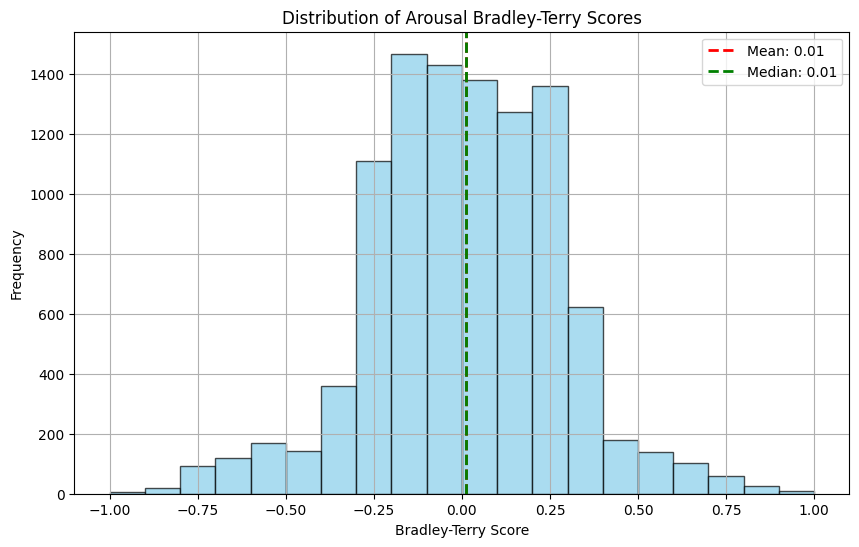

In [16]:
import matplotlib.pyplot as plt

# Plot the distribution
plt.figure(figsize=(10, 6))
emopair_aro.scored_df['Bradley_Terry_Score'].hist(bins=20, alpha=0.7, 
                                                  color='skyblue', edgecolor='black')

# Calculate mean and median
mean_bt = emopair_aro.scored_df['Bradley_Terry_Score'].mean()
median_bt = emopair_aro.scored_df['Bradley_Terry_Score'].median()

# Add vertical lines for mean and median
plt.axvline(mean_bt, color='red', linestyle='dashed', 
            linewidth=2, label=f'Mean: {mean_bt:.2f}')
plt.axvline(median_bt, color='green', linestyle='dashed', 
            linewidth=2, label=f'Median: {median_bt:.2f}')

# Add labels and title
plt.title('Distribution of Arousal Bradley-Terry Scores')
plt.xlabel('Bradley-Terry Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()

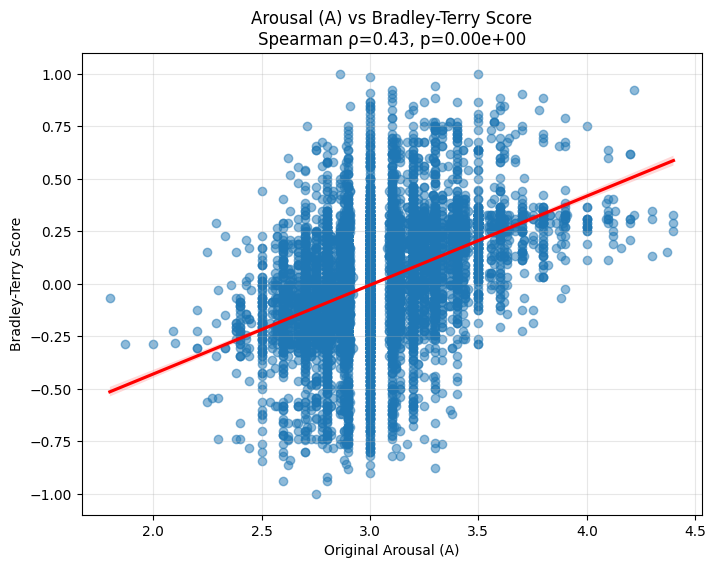

In [19]:
import seaborn as sns
from scipy import stats

plot_data = emopair_aro.scored_df.copy()
plot_data = plot_data.merge(
    emobank[['id', 'A']], 
    left_on='item_id', 
    right_on='id', 
    how='left').drop(columns=['id'])

# Calculate correlation statistics
r, p = stats.spearmanr(plot_data['A'], 
                       plot_data['Bradley_Terry_Score'])

# Create the plot
plt.figure(figsize=(8, 6))
sns.regplot(data=plot_data, x='A', y='Bradley_Terry_Score', 
            scatter_kws={'alpha':0.5}, line_kws={'color': 'red'})

# Add labels and title with stats
plt.title(f'Arousal (A) vs Bradley-Terry Score\nSpearman ρ={r:.2f}, p={p:.2e}')
plt.xlabel('Original Arousal (A)')
plt.ylabel('Bradley-Terry Score')
plt.grid(True, alpha=0.3)
plt.show()

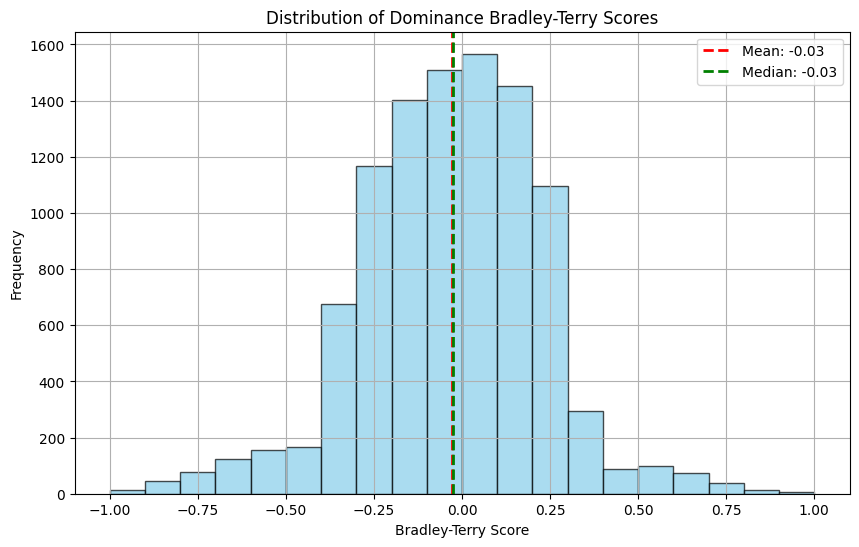

In [23]:
import matplotlib.pyplot as plt

# Plot the distribution
plt.figure(figsize=(10, 6))
emopair_dom.scored_df['Bradley_Terry_Score'].hist(bins=20, alpha=0.7, 
                                                  color='skyblue', edgecolor='black')

# Calculate mean and median
mean_bt = emopair_dom.scored_df['Bradley_Terry_Score'].mean()
median_bt = emopair_dom.scored_df['Bradley_Terry_Score'].median()

# Add vertical lines for mean and median
plt.axvline(mean_bt, color='red', linestyle='dashed', 
            linewidth=2, label=f'Mean: {mean_bt:.2f}')
plt.axvline(median_bt, color='green', linestyle='dashed', 
            linewidth=2, label=f'Median: {median_bt:.2f}')

# Add labels and title
plt.title('Distribution of Dominance Bradley-Terry Scores')
plt.xlabel('Bradley-Terry Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()

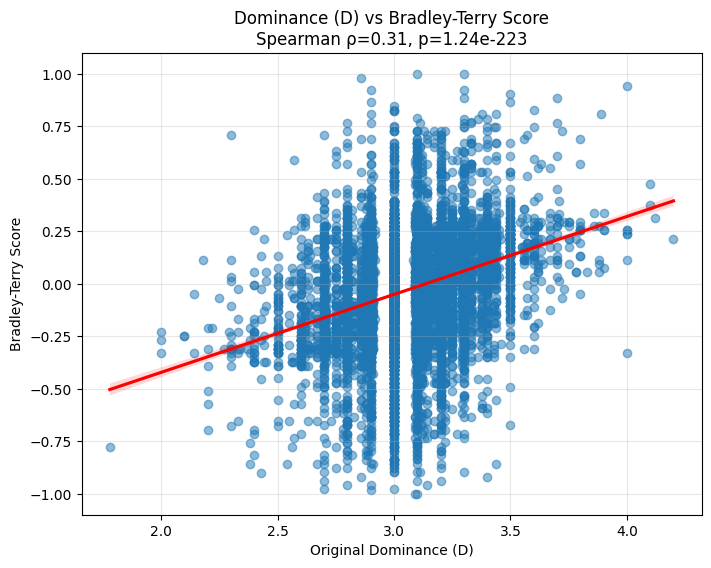

In [24]:
import seaborn as sns
from scipy import stats

plot_data = emopair_dom.scored_df.copy()
plot_data = plot_data.merge(
    emobank[['id', 'D']], 
    left_on='item_id', 
    right_on='id', 
    how='left').drop(columns=['id'])

# Calculate correlation statistics
r, p = stats.spearmanr(plot_data['D'], 
                       plot_data['Bradley_Terry_Score'])

# Create the plot
plt.figure(figsize=(8, 6))
sns.regplot(data=plot_data, x='D', y='Bradley_Terry_Score', 
            scatter_kws={'alpha':0.5}, line_kws={'color': 'red'})

# Add labels and title with stats
plt.title(f'Dominance (D) vs Bradley-Terry Score\nSpearman ρ={r:.2f}, p={p:.2e}')
plt.xlabel('Original Dominance (D)')
plt.ylabel('Bradley-Terry Score')
plt.grid(True, alpha=0.3)
plt.show()

# Save EmoPair pairadigm data

In [27]:
date = pd.Timestamp.now().strftime("%Y-%m-%d")
emopair_aro.pairwise_df.to_csv(f'Results/emopair_aro_untied_pairwise_annotations_{date}.csv', index=False)
emopair_aro.scored_df.to_csv(f'Results/emopair_aro_untied_scores_{date}.csv', index=False)

emopair_dom.pairwise_df.to_csv(f'Results/emopair_dom_untied_pairwise_annotations_{date}.csv', index=False)
emopair_dom.scored_df.to_csv(f'Results/emopair_dom_untied_scores_{date}.csv', index=False)

In [ ]:
# emopair_dom.check_transitivity() WILL TAKE A LONG TIME TO RUN, SO COMMENTING OUT FOR NOW.

# Make EmoPair

In [6]:
cols_to_rename = ['breakdown1', 'breakdown2', 'decision', 'justification']
dimension = ['A', 'D']

In [27]:
aro_scores = emopair_aro.scored_df.rename(columns={'Bradley_Terry_Score': 'A_BT_score_full'}).copy()
dom_scores = emopair_dom.scored_df.rename(columns={'Bradley_Terry_Score': 'D_BT_score_full'}).copy()

In [ ]:
# Filter pairs by split combinations
aro_train_pairs = emopair_aro.pairwise_df[
    (emopair_aro.pairwise_df['item1_split'] == 'train') & 
    (emopair_aro.pairwise_df['item2_split'] == 'train')
].copy()

aro_dev_pairs = emopair_aro.pairwise_df[
    (emopair_aro.pairwise_df['item1_split'] == 'dev') & 
    (emopair_aro.pairwise_df['item2_split'] == 'dev')
].copy()

aro_test_pairs = emopair_aro.pairwise_df[
    (emopair_aro.pairwise_df['item1_split'] == 'test') & 
    (emopair_aro.pairwise_df['item2_split'] == 'test')
].copy()

dom_train_pairs = emopair_dom.pairwise_df[
    (emopair_dom.pairwise_df['item1_split'] == 'train') & 
    (emopair_dom.pairwise_df['item2_split'] == 'train')
].copy()

dom_dev_pairs = emopair_dom.pairwise_df[
    (emopair_dom.pairwise_df['item1_split'] == 'dev') & 
    (emopair_dom.pairwise_df['item2_split'] == 'dev')
].copy()

dom_test_pairs = emopair_dom.pairwise_df[
    (emopair_dom.pairwise_df['item1_split'] == 'test') & 
    (emopair_dom.pairwise_df['item2_split'] == 'test')
].copy()

print(f"Arousal train/train pairs: {len(aro_train_pairs)}")
print(f"Arousal dev/dev pairs: {len(aro_dev_pairs)}")
print(f"Arousal test/test pairs: {len(aro_test_pairs)}")
print(f"Dominance train/train pairs: {len(dom_train_pairs)}")
print(f"Dominance dev/dev pairs: {len(dom_dev_pairs)}")
print(f"Dominance test/test pairs: {len(dom_test_pairs)}")

# Create temporary Pairadigm objects for each split
splits = ['train', 'dev', 'test']
aro_split_pairadigms = {}
dom_split_pairadigms = {}

for split in splits:
    # Arousal
    aro_split_pairadigms[split] = pdm.Pairadigm(
        data=all_pairs,
        paired=True,
        item_id_name='id',
        item_id_cols=['item1', 'item2'],
        item_text_cols=['item1_text', 'item2_text'],
        cgcot_prompts=aro_prompts,
        model_name='gpt-5.1',
        api_key=os.getenv('OPENAI_API_KEY'),
        base_url="https://us.api.openai.com/v1",
        target_concept='arousal'
    )
    
    # Dominance
    dom_split_pairadigms[split] = pdm.Pairadigm(
        data=all_pairs,
        paired=True,
        item_id_name='id',
        item_id_cols=['item1', 'item2'],
        item_text_cols=['item1_text', 'item2_text'],
        cgcot_prompts=dom_prompts,
        model_name='claude-sonnet-4-5',
        api_key=os.getenv('ANTHROPIC_API_KEY'),
        target_concept='dominance'
    )

# Assign filtered pairs to corresponding Pairadigm objects
aro_split_pairadigms['train'].pairwise_df = aro_train_pairs
aro_split_pairadigms['dev'].pairwise_df = aro_dev_pairs
aro_split_pairadigms['test'].pairwise_df = aro_test_pairs

dom_split_pairadigms['train'].pairwise_df = dom_train_pairs
dom_split_pairadigms['dev'].pairwise_df = dom_dev_pairs
dom_split_pairadigms['test'].pairwise_df = dom_test_pairs

# Score items for each split and combine into single dataframes
split_scores_list = []

for split in splits:
    # Score arousal
    aro_split_pairadigms[split].score_items(normalization_scale='negative-one-to-one')
    aro_split_scores = aro_split_pairadigms[split].scored_df[['item_id', 'Bradley_Terry_Score']].rename(
        columns={'Bradley_Terry_Score': 'A_BT_score_split'}
    )
    
    # Score dominance
    dom_split_pairadigms[split].score_items(normalization_scale='negative-one-to-one')
    dom_split_scores = dom_split_pairadigms[split].scored_df[['item_id', 'Bradley_Terry_Score']].rename(
        columns={'Bradley_Terry_Score': 'D_BT_score_split'}
    )
    
    # Merge arousal and dominance scores for this split
    split_score = aro_split_scores.merge(dom_split_scores, on='item_id', how='outer')
    split_scores_list.append(split_score)
    
    print(f"\n{split.capitalize()} scores:")
    print(split_score.head())

split_scores = pd.concat(split_scores_list, ignore_index=True)

In [25]:
split_scores

,item_id,A_BT_score_split,D_BT_score_split
0,110CYL068_1036_1079,-0.080316,-0.311499
1,110CYL068_1127_1130,-0.655125,-0.606478
2,110CYL068_1137_1188,-0.251934,0.226989
3,110CYL068_1189_1328,0.320377,0.421976
4,110CYL068_1475_1558,-0.022278,0.129527
...,...,...,...
10057,wsj_2465_2001_2296,0.876145,-0.258243
10058,wsj_2465_2442_2614,0.570912,-0.012408
10059,wsj_2465_3356_3593,0.185679,0.357045
10060,wwf12_3238_3286,0.510334,-0.753478


In [31]:
# Combine the A and D scores into a single dataframe
all_scores = pd.merge(aro_scores, dom_scores, on='item_id', how='inner')

# Merge the original A and D ratings from emobank into all_scores
all_scores = emobank.merge(
    all_scores,
    left_on='id',
    right_on='item_id',
    how='left').drop(columns=['id'])

# Rescale the original A and D ratings from emobank to be between -1 and 1 instead of 1 and 5
all_scores['A_rescaled'] = (all_scores['A'] - 3) / 2
all_scores['D_rescaled'] = (all_scores['D'] - 3) / 2

# Merge the split scores into all_scores
all_scores = all_scores.merge(split_scores, on='item_id', how='left')

# Put item_id as the first column
cols = ['item_id'] + [col for col in all_scores.columns if col != 'item_id']
all_scores = all_scores[cols]

all_scores

,item_id,split,V,A,D,text,A_BT_score_full,D_BT_score_full,A_rescaled,D_rescaled,A_BT_score_split,D_BT_score_split
0,110CYL068_1036_1079,train,3.00,3.00,3.20,"Remember what she said in my last letter? """,-0.007953,-0.249618,0.000,0.100,-0.080316,-0.311499
1,110CYL068_1079_1110,test,2.80,3.10,2.80,If I wasn't working here.,-0.165819,-0.574112,0.050,-0.100,-0.218244,-0.621851
2,110CYL068_1127_1130,train,3.00,3.00,3.00,"..""",-0.286353,-0.330882,0.000,0.000,-0.655125,-0.606478
3,110CYL068_1137_1188,train,3.44,3.00,3.22,Goodwill helps people get off of public assist...,-0.146604,0.134371,0.000,0.110,-0.251934,0.226989
4,110CYL068_1189_1328,train,3.55,3.27,3.46,Sherry learned through our Future Works class ...,0.170138,0.214993,0.135,0.230,0.320377,0.421976
...,...,...,...,...,...,...,...,...,...,...,...,...
10057,wwf12_4531_4624,train,3.00,3.50,3.00,Please let it be a constant reminder of all yo...,0.268549,-0.128251,0.250,0.000,0.605149,-0.409790
10058,wwf12_501_591,train,3.80,3.40,3.60,That’s why I want to extend my appreciation fo...,-0.067112,0.133948,0.200,0.300,-0.251579,0.129240
10059,wwf12_592_691,train,3.00,3.00,3.10,And why I’m writing you today to ask you to re...,0.150444,-0.047152,0.000,0.050,0.206740,-0.360066
10060,wwf12_702_921,train,3.33,3.44,3.44,"In fact, I want to urge you to strengthen your...",0.366853,0.214345,0.220,0.220,0.775513,0.324047


In [32]:
all_scores.to_csv('Results/emopair.csv', index=False)

In [ ]:
aro_pair_breakdowns = emopair_aro.pairwise_df.copy().rename(columns={
    'breakdown1': 'A_breakdown1',
    'breakdown2': 'A_breakdown2',
    'decision': 'A_decision',
    'justification': 'A_justification'
})

dom_pair_breakdowns = emopair_dom.pairwise_df.copy().rename(columns={
    'breakdown1': 'D_breakdown1',
    'breakdown2': 'D_breakdown2',
    'decision': 'D_decision',
    'justification': 'D_justification'
})[['pair_id', 'D_breakdown1', 'D_breakdown2', 'D_decision', 'D_justification']]

all_breakdowns = aro_pair_breakdowns.merge(
    dom_pair_breakdowns,
    on='pair_id')

all_breakdowns

In [37]:
all_breakdowns.to_csv('emopair_pairs_w_breakdowns.csv', index=False)

# EVERYTHING PAST THIS IS OUT OF DATE, DATA LEAKAGE

Kept pieces related to the tie phenomenon we identified before in case we need to revisit. 

## Build pairadigms

In [ ]:
# emopair_aro.score_items(normalization_scale='negative-one-to-one', 
#                         use_davidson=True)
# run time: 85 minutes

/Users/mlchrzan/opt/anaconda3/envs/emopair/lib/python3.12/site-packages/pairadigm/core.py:3201: RuntimeWarning: invalid value encountered in scalar divide
  denominator += (wins[i, j] + wins[j, i]) / (scores[i] + scores[j])


Davidson model converged in 80 iterations
[default] Davidson model fitted with 58221 comparisons
[default] Including 18547 tie decisions
[default] Mean arousal score: -0.643
[default] Std arousal score: 0.271
Score range: -1.000 to 1.000
25th percentile: -0.828
50th percentile (median): -0.729
75th percentile: -0.547

Highest scoring item on arousal (score: 1.000):
The report charged that Panama's Manuel Noriega is not only in league with the drug traffickers but also is bullying the press as never before.

Lowest scoring item on arousal (score: -1.000):
She took a sip of her drink, plain water because, she had explained earlier, she had never liked the taste of alcohol, then fixed her gaze on me.
mean: -0.643
median: -0.729
std: 0.271
min: -1.000
max: 1.000
count: 10062.000


,id,split,V,A,D,text,CGCoT_Breakdown,Davidson_Score
0,110CYL068_1036_1079,train,3.00,3.00,3.20,"Remember what she said in my last letter? """,Original Text: Remember what she said in my la...,-0.735353
1,110CYL068_1079_1110,test,2.80,3.10,2.80,If I wasn't working here.,Original Text: If I wasn't working here.\nProm...,-0.805996
2,110CYL068_1127_1130,train,3.00,3.00,3.00,"..""","Original Text: ..""\nPrompt 1 response: You onl...",-0.760068
3,110CYL068_1137_1188,train,3.44,3.00,3.22,Goodwill helps people get off of public assist...,Original Text: Goodwill helps people get off o...,-0.883139
4,110CYL068_1189_1328,train,3.55,3.27,3.46,Sherry learned through our Future Works class ...,Original Text: Sherry learned through our Futu...,-0.766052
...,...,...,...,...,...,...,...,...
10057,wwf12_4531_4624,train,3.00,3.50,3.00,Please let it be a constant reminder of all yo...,Original Text: Please let it be a constant rem...,-0.096232
10058,wwf12_501_591,train,3.80,3.40,3.60,That’s why I want to extend my appreciation fo...,Original Text: That’s why I want to extend my ...,-0.881812
10059,wwf12_592_691,train,3.00,3.00,3.10,And why I’m writing you today to ask you to re...,Original Text: And why I’m writing you today t...,-0.514307
10060,wwf12_702_921,train,3.33,3.44,3.44,"In fact, I want to urge you to strengthen your...","Original Text: In fact, I want to urge you to ...",-0.336570


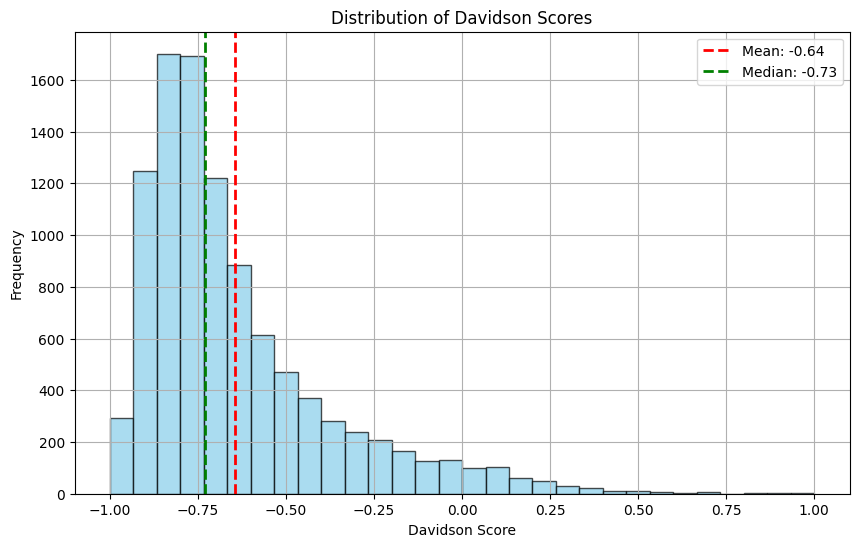

In [ ]:
# emopair_aro.scored_df

# import matplotlib.pyplot as plt

# # Plot the distribution
# plt.figure(figsize=(10, 6))
# emopair_aro.scored_df['Davidson_Score'].hist(bins=30, alpha=0.7, color='skyblue', edgecolor='black')

# # Calculate mean and median
# mean_score = emopair_aro.scored_df['Davidson_Score'].mean()
# median_score = emopair_aro.scored_df['Davidson_Score'].median()

# # Add vertical lines for mean and median
# plt.axvline(mean_score, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {mean_score:.2f}')
# plt.axvline(median_score, color='green', linestyle='dashed', linewidth=2, label=f'Median: {median_score:.2f}')

# # Add labels and title
# plt.title('Distribution of Davidson Scores')
# plt.xlabel('Davidson Score')
# plt.ylabel('Frequency')
# plt.legend()
# plt.show()

In [25]:
emopair_aro.pairwise_df['decision'].value_counts()

decision
Text2    20136
Text1    19538
Tie      18547
Name: count, dtype: int64

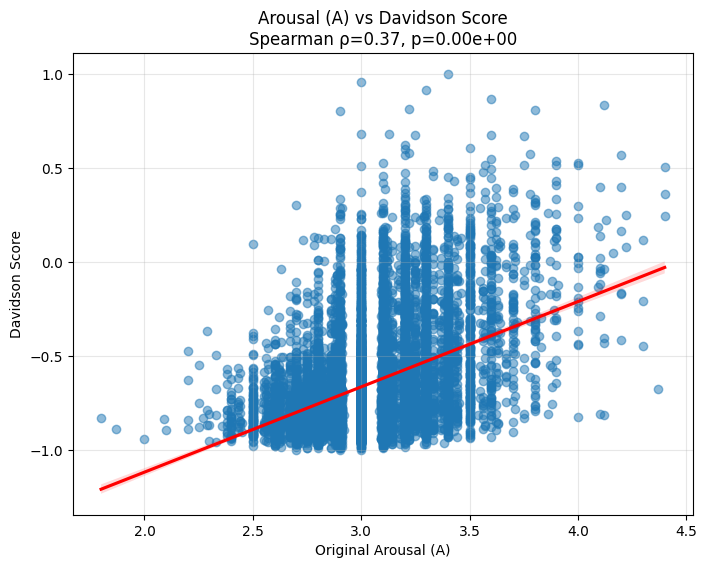

In [ ]:
# import seaborn as sns
# from scipy import stats

# # Calculate correlation statistics
# r, p = stats.spearmanr(emopair_aro.scored_df['A'], emopair_aro.scored_df['Davidson_Score'])

# # Create the plot
# plt.figure(figsize=(8, 6))
# sns.regplot(data=emopair_aro.scored_df, x='A', y='Davidson_Score', 
#             scatter_kws={'alpha':0.5}, line_kws={'color': 'red'})

# # Add labels and title with stats
# plt.title(f'Arousal (A) vs Davidson Score\nSpearman ρ={r:.2f}, p={p:.2e}')
# plt.xlabel('Original Arousal (A)')
# plt.ylabel('Davidson Score')
# plt.grid(True, alpha=0.3)
# plt.show()

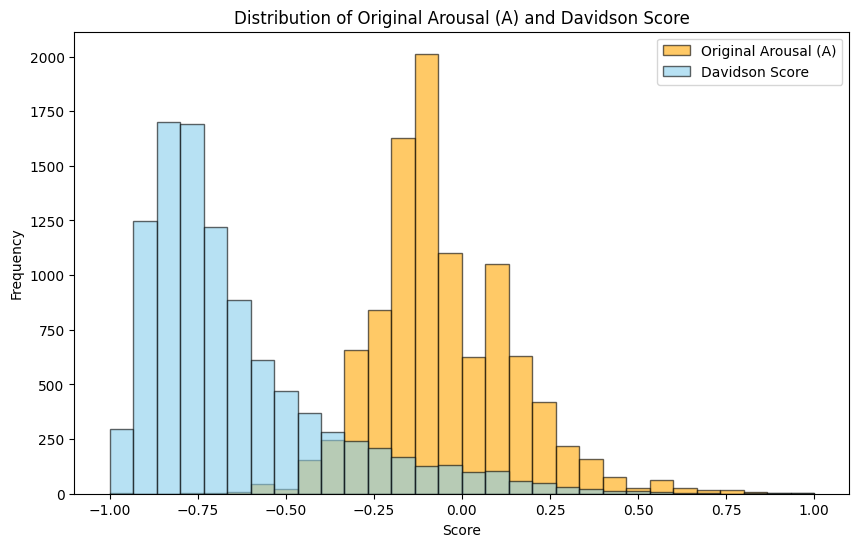

In [ ]:
# Rescale 'A' from original (likely 1-5) to -1 to 1
# A_min, A_max = emopair_aro.scored_df['A'].min(), emopair_aro.scored_df['A'].max()
# emopair_aro.scored_df['A_rescaled'] = 2 * (emopair_aro.scored_df['A'] - A_min) / (A_max - A_min) - 1

plt.figure(figsize=(10, 6))

# Plot histogram for 'A'
plt.hist(emopair_aro.scored_df['A_rescaled'], bins=30, alpha=0.6, color='orange', label='Original Arousal (A)', edgecolor='black')

# Plot histogram for 'Davidson_Score'
plt.hist(emopair_aro.scored_df['Davidson_Score'], bins=30, alpha=0.6, color='skyblue', label='Davidson Score', edgecolor='black')

plt.title('Distribution of Original Arousal (A) and Davidson Score')
plt.xlabel('Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()

## Untied Version

After interrogating the highly skewed distribution and high prevalence of ties in the pairwise annotations, we will build an untied version of the pairadigms by not allowing ties during the pairwise annotation generation step.

From our work in `validate_LLMs.ipynb`, we found that the following LLMs were the best performers without ties allowed:
- Valence: N/A
- Arousal: GPT-5.1
- Dominance: Claude-Sonnet 4.5

Note, everything in the Prep section above needs to be run first.

In [ ]:
# emopair_aro_untied.score_items(normalization_scale='negative-one-to-one')

[default] Bradley-Terry model fitted with 58221 comparisons
[default] Mean arousal score: 0.004
[default] Std arousal score: 0.371
Score range: -1.000 to 1.000
25th percentile: -0.312
50th percentile (median): 0.005
75th percentile: 0.321

Highest scoring item on arousal (score: 1.000):
Apparently the drug use, sexual excess, and weird UCI experiences haven't softened your brain yet.

Lowest scoring item on arousal (score: -1.000):
"wholesale"
mean: 0.004
median: 0.005
std: 0.371
min: -1.000
max: 1.000
count: 10062.000


,id,split,V,A,D,text,CGCoT_Breakdown,Bradley_Terry_Score
0,110CYL068_1036_1079,train,3.00,3.00,3.20,"Remember what she said in my last letter? """,Original Text: Remember what she said in my la...,0.214964
1,110CYL068_1079_1110,test,2.80,3.10,2.80,If I wasn't working here.,Original Text: If I wasn't working here.\nProm...,-0.206263
2,110CYL068_1127_1130,train,3.00,3.00,3.00,"..""","Original Text: ..""\nPrompt 1 response: You onl...",-0.524366
3,110CYL068_1137_1188,train,3.44,3.00,3.22,Goodwill helps people get off of public assist...,Original Text: Goodwill helps people get off o...,-0.417513
4,110CYL068_1189_1328,train,3.55,3.27,3.46,Sherry learned through our Future Works class ...,Original Text: Sherry learned through our Futu...,0.110363
...,...,...,...,...,...,...,...,...
10057,wwf12_4531_4624,train,3.00,3.50,3.00,Please let it be a constant reminder of all yo...,Original Text: Please let it be a constant rem...,0.477870
10058,wwf12_501_591,train,3.80,3.40,3.60,That’s why I want to extend my appreciation fo...,Original Text: That’s why I want to extend my ...,-0.416795
10059,wwf12_592_691,train,3.00,3.00,3.10,And why I’m writing you today to ask you to re...,Original Text: And why I’m writing you today t...,0.372718
10060,wwf12_702_921,train,3.33,3.44,3.44,"In fact, I want to urge you to strengthen your...","Original Text: In fact, I want to urge you to ...",0.582596


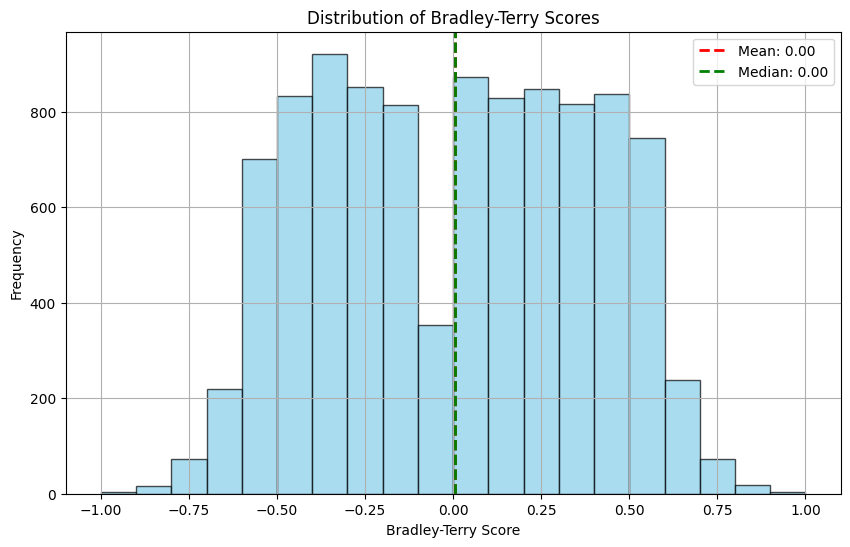

In [53]:
import matplotlib.pyplot as plt

# Plot the distribution
plt.figure(figsize=(10, 6))
emopair_aro_untied.scored_df['Bradley_Terry_Score'].hist(bins=20, alpha=0.7, color='skyblue', edgecolor='black')

# Calculate mean and median
mean_bt = emopair_aro_untied.scored_df['Bradley_Terry_Score'].mean()
median_bt = emopair_aro_untied.scored_df['Bradley_Terry_Score'].median()

# Add vertical lines for mean and median
plt.axvline(mean_bt, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {mean_bt:.2f}')
plt.axvline(median_bt, color='green', linestyle='dashed', linewidth=2, label=f'Median: {median_bt:.2f}')

# Add labels and title
plt.title('Distribution of Bradley-Terry Scores')
plt.xlabel('Bradley-Terry Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()

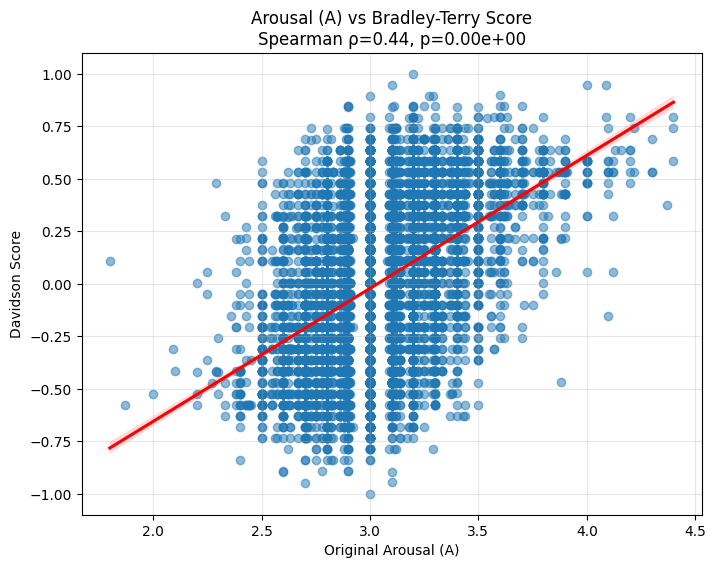

In [56]:
import seaborn as sns
from scipy import stats

# Calculate correlation statistics
r, p = stats.spearmanr(emopair_aro_untied.scored_df['A'], emopair_aro_untied.scored_df['Bradley_Terry_Score'])

# Create the plot
plt.figure(figsize=(8, 6))
sns.regplot(data=emopair_aro_untied.scored_df, x='A', y='Bradley_Terry_Score', 
            scatter_kws={'alpha':0.5}, line_kws={'color': 'red'})

# Add labels and title with stats
plt.title(f'Arousal (A) vs Bradley-Terry Score\nSpearman ρ={r:.2f}, p={p:.2e}')
plt.xlabel('Original Arousal (A)')
plt.ylabel('Davidson Score')
plt.grid(True, alpha=0.3)
plt.show()

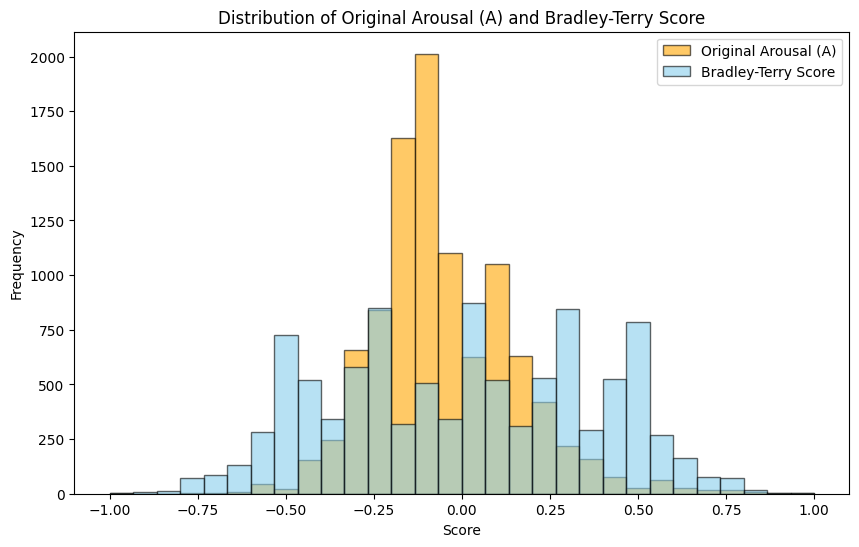

In [57]:
# Rescale 'A' from original (likely 1-5) to -1 to 1
A_min, A_max = emopair_aro_untied.scored_df['A'].min(), emopair_aro_untied.scored_df['A'].max()
emopair_aro_untied.scored_df['A_rescaled'] = 2 * (emopair_aro_untied.scored_df['A'] - A_min) / (A_max - A_min) - 1

plt.figure(figsize=(10, 6))

# Plot histogram for 'A'
plt.hist(emopair_aro_untied.scored_df['A_rescaled'], bins=30, alpha=0.6, color='orange', label='Original Arousal (A)', edgecolor='black')

# Plot histogram for 'Davidson_Score'
plt.hist(emopair_aro_untied.scored_df['Bradley_Terry_Score'], bins=30, alpha=0.6, color='skyblue', label='Bradley-Terry Score', edgecolor='black')

plt.title('Distribution of Original Arousal (A) and Bradley-Terry Score')
plt.xlabel('Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()

## Dominance

In [71]:
mask = emopair_dom_untied.pairwise_df['decision'] == 'ERROR'
emopair_dom_untied.pairwise_df[mask]

,item1,item2,breakdown1,breakdown2,decision,justification
2096,Fermentation_Eminent-Domain_11376_11484,blog-monastery_5375_5427,"Original Text: sorry, I keep forgetting the Fe...",Original Text: This weekend reminded me that I...,ERROR,list index out of range
3363,119CWL041_18_32,Fermentation_Eminent-Domain_11376_11484,"Original Text: March 29, 1999\nPrompt 1 respon...","Original Text: sorry, I keep forgetting the Fe...",ERROR,list index out of range
3545,Fermentation_Eminent-Domain_11376_11484,hotel-california_23970_23991,"Original Text: sorry, I keep forgetting the Fe...",Original Text: “Of course we notice.\nPrompt 1...,ERROR,list index out of range
4020,110CYL200_947_1076,easy_money_2368_2516,"Original Text: Unemployed, homeless and with a...","Original Text: I'm a researcher, I've come int...",ERROR,list index out of range
4270,A_defense_of_Michael_Moore_6101_6239,audubon1_2448_2609,Original Text: This is plausible -- but entire...,Original Text: Because the USDA’s slow-acting ...,ERROR,list index out of range
...,...,...,...,...,...,...
54721,Fermentation_Eminent-Domain_11376_11484,SemEval_978,"Original Text: sorry, I keep forgetting the Fe...",Original Text: No e-Book for Harry Potter VII\...,ERROR,list index out of range
54872,117CWL008_1449_1499,Nathans_Bylichka_27479_27562,Original Text: Thank you in advance for your c...,Original Text: It’s been in our collection for...,ERROR,list index out of range
55694,119CWL041_222_312,audubon1_132_395,Original Text: We must be able to reach all yo...,Original Text: Just imagine finding your favor...,ERROR,list index out of range
56438,Nathans_Bylichka_34187_34243,wildelifewatch1_1094_1237,Original Text: “A little walking should get th...,Original Text: But I also hope you will help u...,ERROR,list index out of range


In [ ]:
# emopair_dom_untied.score_items(normalization_scale='negative-one-to-one')

/Users/mlchrzan/opt/anaconda3/envs/emopair/lib/python3.12/site-packages/pairadigm/core.py:3146: UserWarning:

Some rows filtered out due to invalid decision values. Using 58158/58221 comparisons.



[default] Bradley-Terry model fitted with 58158 comparisons
[default] Mean dominance score: 0.077
[default] Std dominance score: 0.336
Score range: -1.000 to 1.000
25th percentile: -0.216
50th percentile (median): 0.078
75th percentile: 0.370

Highest scoring item on dominance (score: 1.000):
Apparently the drug use, sexual excess, and weird UCI experiences haven't softened your brain yet.

Lowest scoring item on dominance (score: -1.000):
“But …but sir,”
mean: 0.077
median: 0.078
std: 0.336
min: -1.000
max: 1.000
count: 10062.000


,id,split,V,A,D,text,CGCoT_Breakdown,Bradley_Terry_Score
0,110CYL068_1036_1079,train,3.00,3.00,3.20,"Remember what she said in my last letter? """,Original Text: Remember what she said in my la...,-0.314040
1,110CYL068_1079_1110,test,2.80,3.10,2.80,If I wasn't working here.,Original Text: If I wasn't working here.\nProm...,-0.313774
2,110CYL068_1127_1130,train,3.00,3.00,3.00,"..""","Original Text: ..""\nPrompt 1 response: I'd be ...",-0.411762
3,110CYL068_1137_1188,train,3.44,3.00,3.22,Goodwill helps people get off of public assist...,Original Text: Goodwill helps people get off o...,0.758803
4,110CYL068_1189_1328,train,3.55,3.27,3.46,Sherry learned through our Future Works class ...,Original Text: Sherry learned through our Futu...,0.273397
...,...,...,...,...,...,...,...,...
10057,wwf12_4531_4624,train,3.00,3.50,3.00,Please let it be a constant reminder of all yo...,Original Text: Please let it be a constant rem...,-0.167124
10058,wwf12_501_591,train,3.80,3.40,3.60,That’s why I want to extend my appreciation fo...,Original Text: That’s why I want to extend my ...,-0.118160
10059,wwf12_592_691,train,3.00,3.00,3.10,And why I’m writing you today to ask you to re...,Original Text: And why I’m writing you today t...,-0.166372
10060,wwf12_702_921,train,3.33,3.44,3.44,"In fact, I want to urge you to strengthen your...","Original Text: In fact, I want to urge you to ...",0.419108


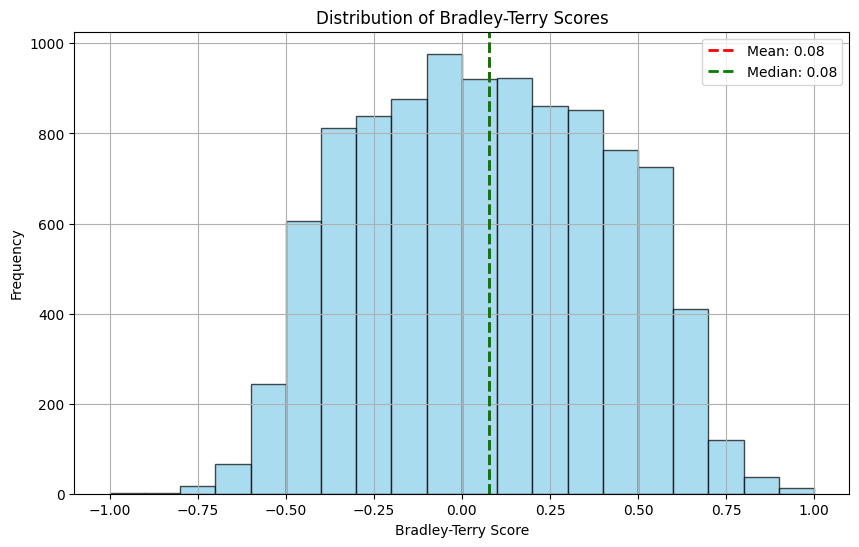

In [9]:
import matplotlib.pyplot as plt

# Plot the distribution
plt.figure(figsize=(10, 6))
emopair_dom_untied.scored_df['Bradley_Terry_Score'].hist(bins=20, alpha=0.7, color='skyblue', edgecolor='black')

# Calculate mean and median
mean_bt = emopair_dom_untied.scored_df['Bradley_Terry_Score'].mean()
median_bt = emopair_dom_untied.scored_df['Bradley_Terry_Score'].median()
# Add vertical lines for mean and median
plt.axvline(mean_bt, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {mean_bt:.2f}')
plt.axvline(median_bt, color='green', linestyle='dashed', linewidth=2, label=f'Median: {median_bt:.2f}')

# Add labels and title
plt.title('Distribution of Bradley-Terry Scores')
plt.xlabel('Bradley-Terry Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()

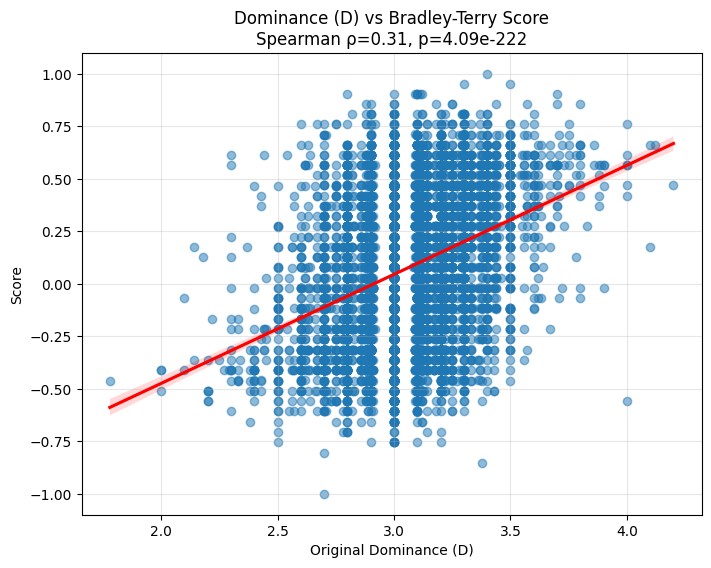

In [10]:
import seaborn as sns
from scipy import stats

# Calculate correlation statistics
r, p = stats.spearmanr(emopair_dom_untied.scored_df['D'], emopair_dom_untied.scored_df['Bradley_Terry_Score'])

# Create the plot
plt.figure(figsize=(8, 6))
sns.regplot(data=emopair_dom_untied.scored_df, x='D', y='Bradley_Terry_Score', 
            scatter_kws={'alpha':0.5}, line_kws={'color': 'red'})

# Add labels and title with stats
plt.title(f'Dominance (D) vs Bradley-Terry Score\nSpearman ρ={r:.2f}, p={p:.2e}')
plt.xlabel('Original Dominance (D)')
plt.ylabel('Score')
plt.grid(True, alpha=0.3)
plt.show()

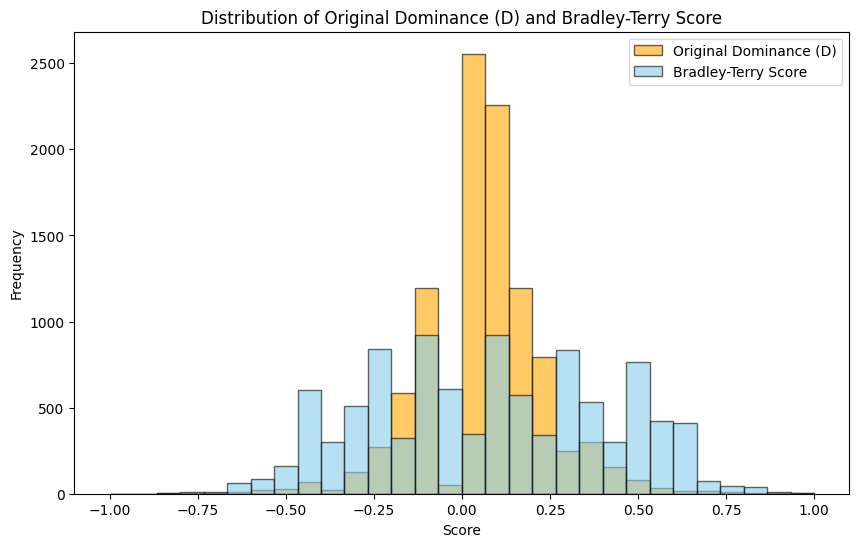

In [11]:
# Rescale 'A' from original (likely 1-5) to -1 to 1
D_min, D_max = emopair_dom_untied.scored_df['D'].min(), emopair_dom_untied.scored_df['D'].max()
emopair_dom_untied.scored_df['D_rescaled'] = 2 * (emopair_dom_untied.scored_df['D'] - D_min) / (D_max - D_min) - 1

plt.figure(figsize=(10, 6))

# Plot histogram for 'A'
plt.hist(emopair_dom_untied.scored_df['D_rescaled'], bins=30, alpha=0.6, color='orange', label='Original Dominance (D)', edgecolor='black')

# Plot histogram for 'Davidson_Score'
plt.hist(emopair_dom_untied.scored_df['Bradley_Terry_Score'], bins=30, alpha=0.6, color='skyblue', label='Bradley-Terry Score', edgecolor='black')

plt.title('Distribution of Original Dominance (D) and Bradley-Terry Score')
plt.xlabel('Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()